# Prédiction de la qualité de soudures — Notebook 2 : Modélisation ML

**Cours de Machine Learning — 3A**
**Équipe n° :** _(à compléter)_ · **Membres / mails :** _(à compléter)_ · **Date :** _(à compléter)_

---

## Objet de ce notebook
Ce notebook met en œuvre la **stratégie ML définie dans le notebook 1**. Il prédit la **ténacité Charpy**
(indicateur n°1 de la qualité d'une soudure) à partir de la composition chimique et des paramètres du procédé.

Au programme :
1. Reprise du dataset nettoyé et **cadrage du problème supervisé** (régression).
2. **Protocole de validation rigoureux** : `Pipeline` (imputation + encodage + scaling + modèle),
   **`GroupKFold`** par campagne expérimentale, jeu de **test mis de côté** (holdout) par groupes.
3. **Comparaison de plusieurs modèles** (baseline, linéaires, k-NN, SVR, forêts, boosting) via validation croisée.
4. **Optimisation des hyperparamètres** des meilleurs modèles.
5. **Évaluation finale** sur le holdout (prédit vs réel, résidus).
6. **Importance des variables** → leviers physiques de la ténacité.
7. **Méthode semi-supervisée** (self-training / pseudo-labelling) exploitant les lignes non labellisées + comparaison.
8. **Conclusion** : meilleure approche et **recommandations métier**.

### Rappel des métriques (régression)
Pour une prédiction $\hat{y}_i$ d'une valeur réelle $y_i$ sur $n$ échantillons :
- **RMSE** $= \sqrt{\frac{1}{n}\sum_i (y_i-\hat{y}_i)^2}$ — erreur quadratique moyenne, en Joules ; pénalise fortement les grosses erreurs.
- **MAE** $= \frac{1}{n}\sum_i |y_i-\hat{y}_i|$ — erreur absolue moyenne, en Joules ; interprétation métier directe.
- **R²** $= 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}$ — part de variance expliquée (1 = parfait, 0 = équivalent à prédire la moyenne).


## 1. Imports et configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, warnings
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
print("Librairies chargées.")

Librairies chargées.


## 2. Données, cible et groupes

On repart du dataset nettoyé `data/welddb_clean.csv` produit par le notebook 1.

### 2.1 Cadrage supervisé
- **y = `CharpyToughness`** (ténacité, en J) — on ne garde que les lignes **labellisées** pour l'apprentissage supervisé.
- **X = composition chimique + paramètres procédé + `CharpyTemp`**. `CharpyTemp` est une feature
  **obligatoire** : la même soudure est tenace à chaud et fragile à froid (cf. notebook 1).
- **Variables catégorielles** : `AC_DC`, `Polarity`, `WeldType` (encodage one-hot).

### 2.2 Groupes pour éviter la fuite de données
`WeldID` est presque unique par ligne, mais plusieurs lignes proviennent d'une **même campagne
expérimentale** (même auteur/étude/année), avec des compositions très proches. Si une ligne d'une
campagne est en apprentissage et sa quasi-jumelle en test, on **surestime** la performance.
On construit donc une clé de **groupe = préfixe de campagne** (ex. `Evans-AlTi-1994`) et on l'utilise
pour **`GroupKFold`** et pour le découpage train/test.

In [2]:
df = pd.read_csv("data/welddb_clean.csv")

# Clé de groupe = préfixe de campagne (avant l'année sur 4 chiffres)
def campaign(x):
    x = str(x)
    m = re.match(r"^(.*?-\d{4})", x)
    return m.group(1) if m else x
df["group"] = df["WeldID"].map(campaign)

TARGET = "CharpyToughness"
FEATURES_NUM = ["C","Si","Mn","S","P","Ni","Cr","Mo","V","Cu","O_ppm","Ti_ppm","N_ppm",
                "Al_ppm","Current","Voltage","HeatInput","InterpassTemp",
                "PWHT_temp","PWHT_time","CharpyTemp"]
FEATURES_CAT = ["AC_DC","Polarity","WeldType"]
FEATURES = FEATURES_NUM + FEATURES_CAT

print("Lignes totales :", len(df), "| groupes (campagnes) :", df['group'].nunique())
print("Lignes labellisées (Charpy renseigné) :", df[TARGET].notna().sum())

Lignes totales : 1652 | groupes (campagnes) : 353
Lignes labellisées (Charpy renseigné) : 879


In [3]:
# Jeu supervisé : lignes avec label Charpy
sup = df[df[TARGET].notna()].copy()
X = sup[FEATURES].copy()
y = sup[TARGET].astype(float).values
groups = sup["group"].values
print("X supervisé :", X.shape, "| y :", y.shape, "| groupes :", pd.Series(groups).nunique())
print("\nStatistiques de la cible Charpy (J) :")
print(pd.Series(y).describe().round(1))

X supervisé : (879, 24) | y : (879,) | groupes : 220

Statistiques de la cible Charpy (J) :
count    879.0
mean      87.7
std       50.1
min        3.0
25%       38.0
50%      100.0
75%      100.0
max      270.0
dtype: float64


## 3. Découpage train / test par groupes et pré-traitement

### 3.1 Holdout de test (20 %) par groupes
On met de côté ~20 % des **campagnes** (pas des lignes) pour un test final honnête : aucune campagne du
test n'apparaît à l'apprentissage.

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[tr_idx], X.iloc[te_idx]
y_train, y_test = y[tr_idx], y[te_idx]
g_train = groups[tr_idx]
print(f"Train : {len(X_train)} lignes / {pd.Series(g_train).nunique()} campagnes")
print(f"Test  : {len(X_test)} lignes / {pd.Series(groups[te_idx]).nunique()} campagnes")
# Vérif : aucune campagne commune
assert set(groups[tr_idx]).isdisjoint(set(groups[te_idx])), "Fuite de groupe !"
print("OK : aucune campagne partagée entre train et test.")

Train : 756 lignes / 176 campagnes
Test  : 123 lignes / 44 campagnes
OK : aucune campagne partagée entre train et test.


### 3.2 Pré-traitement (dans un `ColumnTransformer`)
- **Numériques** : imputation par la **médiane** + **standardisation** (centrage-réduction).
- **Catégorielles** : imputation par le mode + **one-hot encoding**.

Tout est encapsulé dans un `Pipeline` : le pré-traitement est **ré-ajusté à chaque pli** de validation
croisée, sur le train uniquement → **aucune fuite de données**.

In [5]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, FEATURES_NUM),
    ("cat", categorical_pipe, FEATURES_CAT),
])
print("Pré-traitement défini (num: médiane+scale | cat: mode+onehot).")

Pré-traitement défini (num: médiane+scale | cat: mode+onehot).


## 4. Comparaison des modèles par validation croisée

On évalue chaque modèle par **`GroupKFold` (5 plis)** sur le train, avec les 3 métriques. On compare
toujours à une **baseline naïve** (prédire la moyenne) : un modèle n'a d'intérêt que s'il la bat nettement.

In [6]:
from sklearn import clone

def make_pipe(model):
    # clone -> chaque pipeline possède SON préprocesseur (pas d'état partagé)
    return Pipeline([("prep", clone(preprocess)), ("model", model)])

models = {
    "Baseline (moyenne)" : DummyRegressor(strategy="mean"),
    "Ridge"              : Ridge(random_state=RANDOM_STATE),
    "Lasso"              : Lasso(random_state=RANDOM_STATE, max_iter=10000),
    "k-NN"               : KNeighborsRegressor(n_neighbors=7),
    "SVR (RBF)"          : SVR(C=10, gamma="scale"),
    "Random Forest"      : RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting"  : GradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = GroupKFold(n_splits=5)
scoring = {"rmse":"neg_root_mean_squared_error",
           "mae":"neg_mean_absolute_error",
           "r2":"r2"}

rows = []
for name, mdl in models.items():
    res = cross_validate(make_pipe(mdl), X_train, y_train, groups=g_train,
                         cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "Modèle": name,
        "RMSE (J)": -res["test_rmse"].mean(), "RMSE_std": res["test_rmse"].std(),
        "MAE (J)":  -res["test_mae"].mean(),
        "R²": res["test_r2"].mean(), "R²_std": res["test_r2"].std(),
    })
cv_results = pd.DataFrame(rows).sort_values("RMSE (J)").reset_index(drop=True)
cv_results.round(3)

,Modèle,RMSE (J),RMSE_std,MAE (J),R²,R²_std
0,Ridge,39.003,5.115,30.745,0.231,0.134
1,SVR (RBF),40.734,11.601,32.061,0.215,0.132
2,Random Forest,41.205,11.095,30.258,0.153,0.287
3,Gradient Boosting,41.304,10.404,31.018,0.153,0.257
4,Lasso,42.120,9.353,34.294,0.122,0.229
5,k-NN,42.132,10.428,32.255,0.141,0.154
6,Baseline (moyenne),46.952,10.757,37.127,-0.062,0.053


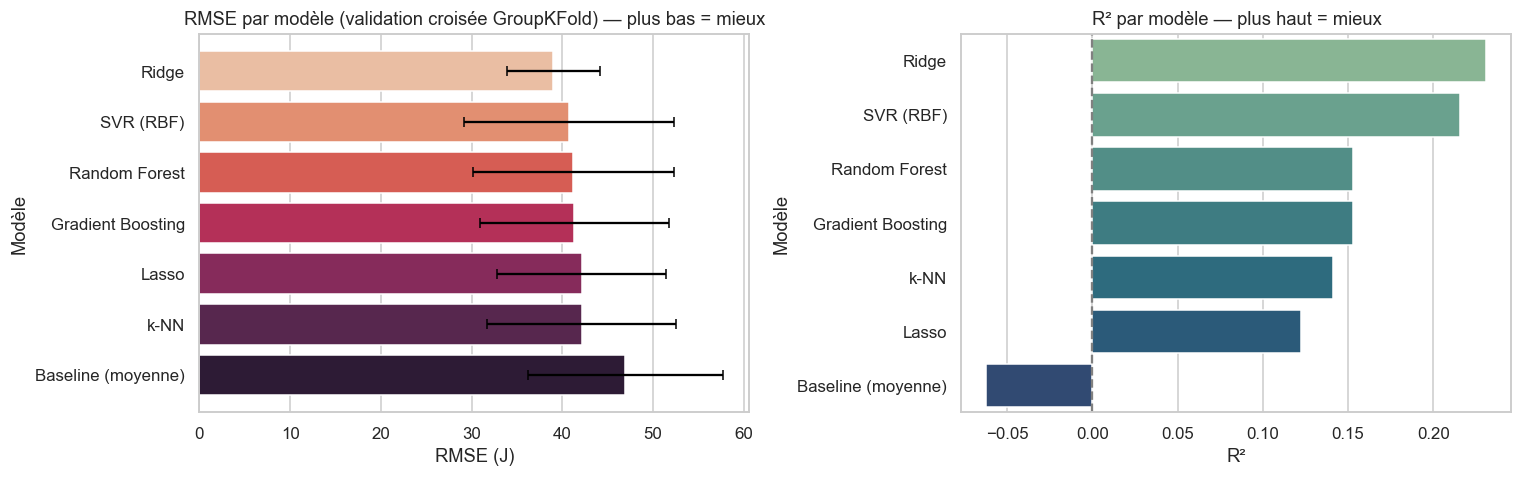

Meilleur modèle en CV (RMSE) : Ridge


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
d = cv_results.sort_values("RMSE (J)")
sns.barplot(data=d, y="Modèle", x="RMSE (J)", ax=axes[0], palette="rocket_r")
axes[0].errorbar(d["RMSE (J)"], range(len(d)), xerr=d["RMSE_std"], fmt="none", ecolor="black", capsize=3)
axes[0].set_title("RMSE par modèle (validation croisée GroupKFold) — plus bas = mieux")
d2 = cv_results.sort_values("R²", ascending=False)
sns.barplot(data=d2, y="Modèle", x="R²", ax=axes[1], palette="crest")
axes[1].axvline(0, color="grey", ls="--"); axes[1].set_title("R² par modèle — plus haut = mieux")
plt.tight_layout(); plt.show()
best_name = cv_results.iloc[0]["Modèle"]
print("Meilleur modèle en CV (RMSE) :", best_name)

## 4.bis Modélisation de **chacune** des variables cibles (R² par cible)

Le notebook se concentre sur la ténacité Charpy, mais le notebook d'exploration a retenu **6 propriétés
mécaniques** comme mesures de la qualité. On entraîne ici la **même batterie de modèles** sur **chaque
cible**, avec un protocole identique (`Pipeline` imputation+encodage+scaling, **`GroupKFold`** par campagne),
et on **reporte le R²** (ainsi que RMSE et MAE) pour chacune.

**Règles appliquées :**
- **Features = composition + procédé** pour toutes les cibles.
- `CharpyTemp` est ajoutée **uniquement** pour prédire `CharpyToughness` (c'est une condition d'essai propre
  à la ténacité, pas un paramètre de fabrication).
- On ne garde, pour chaque cible, que les lignes où elle est **labellisée** → le nombre d'exemples varie
  d'une cible à l'autre (indiqué dans chaque tableau).

> ⚠️ `Hardness` n'a que ~138 mesures : son R² sera **peu fiable / très variable** et doit être interprété
> avec prudence.


In [8]:
# --- Batterie de modèles et évaluation d'une cible quelconque ---------------
from sklearn import clone as _clone

FEATURES_NUM_BASE = ["C","Si","Mn","S","P","Ni","Cr","Mo","V","Cu","O_ppm","Ti_ppm","N_ppm",
                     "Al_ppm","Current","Voltage","HeatInput","InterpassTemp","PWHT_temp","PWHT_time"]
ALL_TARGETS = ["CharpyToughness","YieldStrength","UTS","Elongation","ReductionArea","Hardness"]

models_mt = {
    "Baseline (moyenne)" : DummyRegressor(strategy="mean"),
    "Ridge"              : Ridge(random_state=RANDOM_STATE),
    "Lasso"              : Lasso(random_state=RANDOM_STATE, max_iter=10000),
    "k-NN"               : KNeighborsRegressor(n_neighbors=7),
    "SVR (RBF)"          : SVR(C=10, gamma="scale"),
    "Random Forest"      : RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting"  : GradientBoostingRegressor(random_state=RANDOM_STATE),
}
scoring_mt = {"r2":"r2", "rmse":"neg_root_mean_squared_error", "mae":"neg_mean_absolute_error"}

def eval_target(target):
    num = FEATURES_NUM_BASE + (["CharpyTemp"] if target == "CharpyToughness" else [])
    cat = FEATURES_CAT
    d = df[df[target].notna()].copy()
    X = d[num + cat]; y = d[target].astype(float).values; g = d["group"].values
    n_groups = pd.Series(g).nunique()
    n_splits = min(5, n_groups)
    prep = ColumnTransformer([
        ("num", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), num),
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    rows = []
    for name, mdl in models_mt.items():
        pipe = Pipeline([("prep", _clone(prep)), ("model", mdl)])
        res = cross_validate(pipe, X, y, groups=g, cv=GroupKFold(n_splits=n_splits),
                             scoring=scoring_mt, n_jobs=-1)
        rows.append({"Modèle":name,
                     "R²":res["test_r2"].mean(), "R²_std":res["test_r2"].std(),
                     "RMSE":-res["test_rmse"].mean(), "MAE":-res["test_mae"].mean()})
    out = pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True)
    return out, len(d), n_groups

print("Fonction eval_target prête. Cibles à traiter :", ALL_TARGETS)

Fonction eval_target prête. Cibles à traiter : ['CharpyToughness', 'YieldStrength', 'UTS', 'Elongation', 'ReductionArea', 'Hardness']


In [9]:
# --- Boucle sur toutes les cibles : tableau détaillé + R² par cible ---------
per_target = {}
for t in ALL_TARGETS:
    res, n, ng = eval_target(t)
    per_target[t] = res
    unit = {"CharpyToughness":"J","YieldStrength":"MPa","UTS":"MPa",
            "Elongation":"%","ReductionArea":"%","Hardness":"kg/mm²"}.get(t,"")
    best = res.iloc[0]
    rf = res[res["Modèle"]=="Random Forest"].iloc[0]
    print("="*78)
    print(f"CIBLE : {t}  ({unit})   |  {n} exemples, {ng} campagnes")
    print(f"  --> Meilleur modèle : {best['Modèle']:18}  R² = {best['R²']:.3f}")
    print(f"  --> Random Forest   : R² = {rf['R²']:.3f}  (RMSE={rf['RMSE']:.1f}, MAE={rf['MAE']:.1f} {unit})")
    display(res.round(3))

CIBLE : CharpyToughness  (J)   |  879 exemples, 220 campagnes
  --> Meilleur modèle : Ridge               R² = 0.294
  --> Random Forest   : R² = 0.227  (RMSE=40.9, MAE=29.6 J)


,Modèle,R²,R²_std,RMSE,MAE
0,Ridge,0.294,0.114,39.796,31.593
1,Gradient Boosting,0.264,0.161,40.349,30.695
2,SVR (RBF),0.227,0.069,42.104,33.869
3,Random Forest,0.227,0.236,40.912,29.609
4,k-NN,0.181,0.148,43.629,33.973
5,Lasso,0.127,0.333,43.405,34.621
6,Baseline (moyenne),-0.061,0.046,49.558,39.119


CIBLE : YieldStrength  (MPa)   |  780 exemples, 150 campagnes
  --> Meilleur modèle : Gradient Boosting   R² = 0.413
  --> Random Forest   : R² = 0.323  (RMSE=70.8, MAE=53.5 MPa)


,Modèle,R²,R²_std,RMSE,MAE
0,Gradient Boosting,0.413,0.236,65.601,48.997
1,Random Forest,0.323,0.238,70.788,53.468
2,SVR (RBF),0.210,0.157,78.210,58.851
3,Lasso,0.094,0.152,83.443,64.291
4,k-NN,0.089,0.204,84.007,64.395
5,Ridge,-0.025,0.239,88.056,68.447
6,Baseline (moyenne),-0.159,0.099,93.983,73.991


CIBLE : UTS  (MPa)   |  738 exemples, 142 campagnes
  --> Meilleur modèle : Gradient Boosting   R² = 0.612
  --> Random Forest   : R² = 0.555  (RMSE=58.1, MAE=41.6 MPa)


...

,Modèle,R²,R²_std,RMSE,MAE
0,Gradient Boosting,0.319,0.191,3.812,3.006
1,SVR (RBF),0.239,0.200,4.053,3.169
2,Random Forest,0.222,0.359,4.022,3.084
3,k-NN,0.132,0.347,4.283,3.371
4,Lasso,0.108,0.107,4.425,3.593
5,Baseline (moyenne),-0.118,0.129,4.963,4.118
6,Ridge,-0.268,0.512,5.144,4.053


CIBLE : ReductionArea  (%)   |  705 exemples, 130 campagnes
  --> Meilleur modèle : SVR (RBF)           R² = 0.360
  --> Random Forest   : R² = 0.293  (RMSE=6.8, MAE=4.3 %)


,Modèle,R²,R²_std,RMSE,MAE
0,SVR (RBF),0.360,0.133,6.653,4.170
1,Random Forest,0.293,0.234,6.835,4.277
2,Lasso,0.230,0.298,7.078,4.797
3,Gradient Boosting,0.205,0.292,7.227,4.655
4,k-NN,0.190,0.256,7.423,4.887
5,Ridge,0.062,0.381,7.733,5.314
6,Baseline (moyenne),-0.139,0.149,8.973,6.877


CIBLE : Hardness  (kg/mm²)   |  138 exemples, 5 campagnes
  --> Meilleur modèle : SVR (RBF)           R² = -3.797
  --> Random Forest   : R² = -7.333  (RMSE=58.2, MAE=46.9 kg/mm²)


,Modèle,R²,R²_std,RMSE,MAE
0,SVR (RBF),-3.797,3.864,50.880,42.163
1,Baseline (moyenne),-4.311,6.589,50.453,41.051
2,Random Forest,-7.333,6.977,58.211,46.904
3,k-NN,-8.008,9.709,61.608,53.746
4,Gradient Boosting,-8.092,8.077,59.527,49.861
5,Lasso,-11.070,11.333,67.155,57.135
6,Ridge,-32.565,36.707,93.719,87.774


### Synthèse : R² de chaque modèle pour chaque cible
Tableau récapitulatif (lignes = modèles, colonnes = cibles) et carte thermique associée. **Plus le R² est
proche de 1, mieux c'est ; un R² ≤ 0 signifie que le modèle ne fait pas mieux que prédire la moyenne.**

R² par modèle (lignes) et par cible (colonnes) :


,CharpyToughness,YieldStrength,UTS,Elongation,ReductionArea,Hardness
Modèle,,,,,,
Random Forest,0.227,0.323,0.555,0.222,0.293,-7.333
Gradient Boosting,0.264,0.413,0.612,0.319,0.205,-8.092
SVR (RBF),0.227,0.210,0.354,0.239,0.360,-3.797
Ridge,0.294,-0.025,0.318,-0.268,0.062,-32.565
Lasso,0.127,0.094,0.412,0.108,0.230,-11.070
k-NN,0.181,0.089,0.245,0.132,0.190,-8.008
Baseline (moyenne),-0.061,-0.159,-0.035,-0.118,-0.139,-4.311


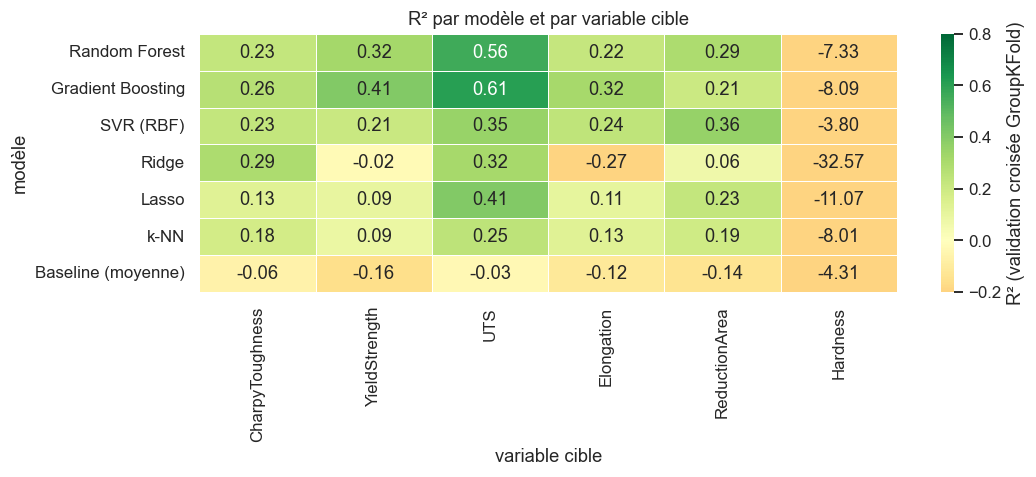


>>> R² du RANDOM FOREST par cible (du meilleur au moins bon) :
    UTS             : R² = 0.555
    YieldStrength   : R² = 0.323
    ReductionArea   : R² = 0.293
    CharpyToughness : R² = 0.227
    Elongation      : R² = 0.222
    Hardness        : R² = -7.333


In [10]:
# --- Matrice récapitulative des R² (modèle x cible) -------------------------
r2_matrix = pd.DataFrame({t: per_target[t].set_index("Modèle")["R²"] for t in ALL_TARGETS})
# ordre lignes = modèles (hors baseline en bas)
order = ["Random Forest","Gradient Boosting","SVR (RBF)","Ridge","Lasso","k-NN","Baseline (moyenne)"]
r2_matrix = r2_matrix.reindex(order)
print("R² par modèle (lignes) et par cible (colonnes) :")
display(r2_matrix.round(3))

plt.figure(figsize=(10,4.5))
import numpy as _np
sns.heatmap(r2_matrix, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-0.2, vmax=0.8,
            cbar_kws={"label":"R² (validation croisée GroupKFold)"}, linewidths=.4)
plt.title("R² par modèle et par variable cible")
plt.ylabel("modèle"); plt.xlabel("variable cible")
plt.tight_layout(); plt.show()

# Récap compact : R² du Random Forest par cible (ce que tu voulais voir)
rf_r2 = r2_matrix.loc["Random Forest"].sort_values(ascending=False)
print("\n>>> R² du RANDOM FOREST par cible (du meilleur au moins bon) :")
for t,v in rf_r2.items():
    print(f"    {t:16}: R² = {v:.3f}")

### Lecture des résultats multi-cibles
- Comparer le **R² par cible** permet de voir **quelles propriétés sont les plus prévisibles** à partir de
  la composition et du procédé (certaines sont intrinsèquement plus faciles à modéliser que d'autres).
- Un **R² faible ou négatif** pour une cible signale soit un manque de données (cf. `Hardness`), soit que
  les features disponibles n'expliquent pas bien cette propriété → piste de discussion pour le rapport.
- Les modèles **d'ensemble** (Random Forest / Gradient Boosting) sont généralement les plus robustes sur
  l'ensemble des cibles ; les écarts entre cibles sont souvent plus importants que les écarts entre modèles.


### 4.ter Optimisation des hyperparamètres (GridSearch) **pour chaque cible**

Dans la section 4.bis les modèles tournaient avec leurs **réglages par défaut**. On applique maintenant un
**`GridSearchCV`** (toujours en `GroupKFold` par campagne, score optimisé = **R²**) à **chaque famille de
modèles** et **pour chaque cible**. On reporte, par cible, le **R² optimisé** de chaque modèle et les
**meilleurs hyperparamètres**, puis on compare au R² par défaut.

In [11]:
# --- Grilles d'hyperparamètres par modèle ----------------------------------
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Ridge":             (Ridge(random_state=RANDOM_STATE),
                          {"model__alpha":[0.1,1,10,100]}),
    "Lasso":             (Lasso(random_state=RANDOM_STATE, max_iter=10000),
                          {"model__alpha":[0.01,0.1,1,10]}),
    "k-NN":              (KNeighborsRegressor(),
                          {"model__n_neighbors":[3,5,7,11,15]}),
    "SVR (RBF)":         (SVR(),
                          {"model__C":[1,10,100], "model__gamma":["scale",0.01,0.1]}),
    "Random Forest":     (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                          {"model__n_estimators":[300,600], "model__max_depth":[None,10,20],
                           "model__min_samples_leaf":[1,2,4]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"model__n_estimators":[200,400], "model__learning_rate":[0.05,0.1],
                           "model__max_depth":[2,3]}),
}

def tune_target(target):
    num = FEATURES_NUM_BASE + (["CharpyTemp"] if target == "CharpyToughness" else [])
    cat = FEATURES_CAT
    d = df[df[target].notna()].copy()
    X = d[num+cat]; y = d[target].astype(float).values; g = d["group"].values
    n_splits = min(5, pd.Series(g).nunique())
    prep = ColumnTransformer([
        ("num", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), num),
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    rows = []
    for name,(mdl,grid) in param_grids.items():
        pipe = Pipeline([("prep", _clone(prep)), ("model", mdl)])
        gs = GridSearchCV(pipe, grid, scoring="r2", cv=GroupKFold(n_splits=n_splits), n_jobs=-1)
        gs.fit(X, y, groups=g)
        rows.append({"Modèle":name, "R² (optimisé)":gs.best_score_,
                     "meilleurs params":{k.replace('model__',''):v for k,v in gs.best_params_.items()}})
    return pd.DataFrame(rows).sort_values("R² (optimisé)", ascending=False).reset_index(drop=True)

print("Fonction tune_target prête — lancement du GridSearch sur les 6 cibles (peut prendre quelques minutes)...")

Fonction tune_target prête — lancement du GridSearch sur les 6 cibles (peut prendre quelques minutes)...


In [12]:
# --- GridSearch sur chaque cible : tableaux + meilleurs R² ------------------
per_target_tuned = {}
for t in ALL_TARGETS:
    res = tune_target(t)
    per_target_tuned[t] = res
    best = res.iloc[0]
    rf = res[res["Modèle"]=="Random Forest"].iloc[0]
    print("="*80)
    print(f"CIBLE : {t}")
    print(f"  --> Meilleur modèle optimisé : {best['Modèle']:18} R² = {best['R² (optimisé)']:.3f}")
    print(f"      params : {best['meilleurs params']}")
    print(f"  --> Random Forest optimisé   : R² = {rf['R² (optimisé)']:.3f}  | params : {rf['meilleurs params']}")
    display(res.round(3))

CIBLE : CharpyToughness
  --> Meilleur modèle optimisé : SVR (RBF)          R² = 0.326
      params : {'C': 100, 'gamma': 'scale'}
  --> Random Forest optimisé   : R² = 0.227  | params : {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}


,Modèle,R² (optimisé),meilleurs params
0,SVR (RBF),0.326,"{'C': 100, 'gamma': 'scale'}"
1,Ridge,0.294,{'alpha': 1}
2,Lasso,0.283,{'alpha': 0.01}
3,Gradient Boosting,0.258,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
4,Random Forest,0.227,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es..."
5,k-NN,0.195,{'n_neighbors': 11}


CIBLE : YieldStrength
  --> Meilleur modèle optimisé : Gradient Boosting  R² = 0.450
      params : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 400}
  --> Random Forest optimisé   : R² = 0.328  | params : {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}


,Modèle,R² (optimisé),meilleurs params
0,Gradient Boosting,0.450,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
1,SVR (RBF),0.378,"{'C': 100, 'gamma': 'scale'}"
2,Random Forest,0.328,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es..."
3,Lasso,0.201,{'alpha': 10}
4,Ridge,0.147,{'alpha': 100}
5,k-NN,0.112,{'n_neighbors': 15}


CIBLE : UTS
  --> Meilleur modèle optimisé : Gradient Boosting  R² = 0.635
      params : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
  --> Random Forest optimisé   : R² = 0.573  | params : {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}


...

,Modèle,R² (optimisé),meilleurs params
0,Gradient Boosting,0.329,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
1,SVR (RBF),0.243,"{'C': 10, 'gamma': 0.1}"
2,Random Forest,0.229,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es..."
3,k-NN,0.147,{'n_neighbors': 11}
4,Lasso,0.108,{'alpha': 1}
5,Ridge,0.009,{'alpha': 100}


CIBLE : ReductionArea
  --> Meilleur modèle optimisé : SVR (RBF)          R² = 0.396
      params : {'C': 100, 'gamma': 0.1}
  --> Random Forest optimisé   : R² = 0.308  | params : {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 600}


,Modèle,R² (optimisé),meilleurs params
0,SVR (RBF),0.396,"{'C': 100, 'gamma': 0.1}"
1,Random Forest,0.308,"{'max_depth': None, 'min_samples_leaf': 4, 'n_..."
2,Ridge,0.305,{'alpha': 100}
3,Lasso,0.256,{'alpha': 0.1}
4,Gradient Boosting,0.202,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
5,k-NN,0.198,{'n_neighbors': 5}


CIBLE : Hardness
  --> Meilleur modèle optimisé : SVR (RBF)          R² = -2.599
      params : {'C': 100, 'gamma': 0.01}
  --> Random Forest optimisé   : R² = -6.526  | params : {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 600}


,Modèle,R² (optimisé),meilleurs params
0,SVR (RBF),-2.599,"{'C': 100, 'gamma': 0.01}"
1,Ridge,-3.307,{'alpha': 10}
2,Lasso,-5.094,{'alpha': 10}
3,Random Forest,-6.526,"{'max_depth': 10, 'min_samples_leaf': 4, 'n_es..."
4,k-NN,-7.294,{'n_neighbors': 15}
5,Gradient Boosting,-8.166,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."


### Récapitulatif : R² optimisé (modèle × cible) et gain apporté par le tuning

R² OPTIMISÉ par modèle (lignes) et par cible (colonnes) :


,CharpyToughness,YieldStrength,UTS,Elongation,ReductionArea,Hardness
Modèle,,,,,,
Random Forest,0.227,0.328,0.573,0.229,0.308,-6.526
Gradient Boosting,0.258,0.450,0.635,0.329,0.202,-8.166
SVR (RBF),0.326,0.378,0.521,0.243,0.396,-2.599
Ridge,0.294,0.147,0.433,0.009,0.305,-3.307
Lasso,0.283,0.201,0.432,0.108,0.256,-5.094
k-NN,0.195,0.112,0.277,0.147,0.198,-7.294


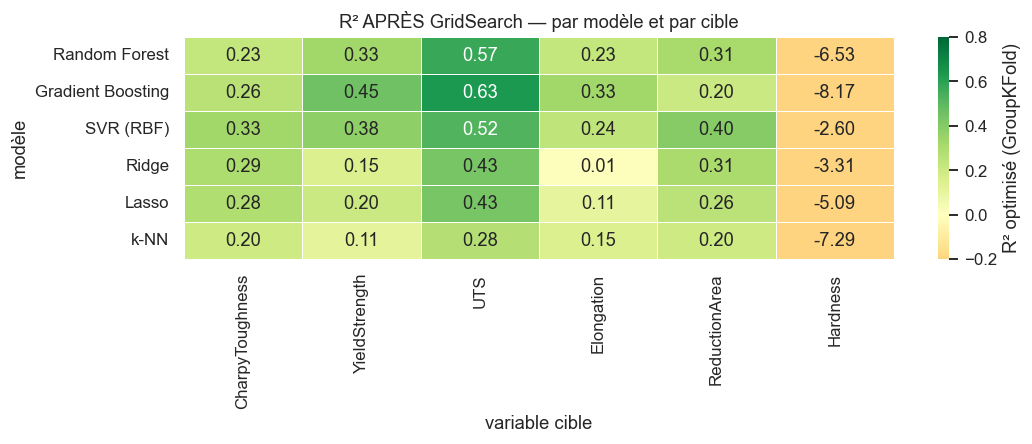


Meilleur R² par cible — défaut vs optimisé :


,R² meilleur (défaut),R² meilleur (optimisé),gain
UTS,0.612,0.635,0.023
YieldStrength,0.413,0.450,0.037
ReductionArea,0.360,0.396,0.035
Elongation,0.319,0.329,0.010
CharpyToughness,0.294,0.326,0.032
Hardness,-3.797,-2.599,1.198


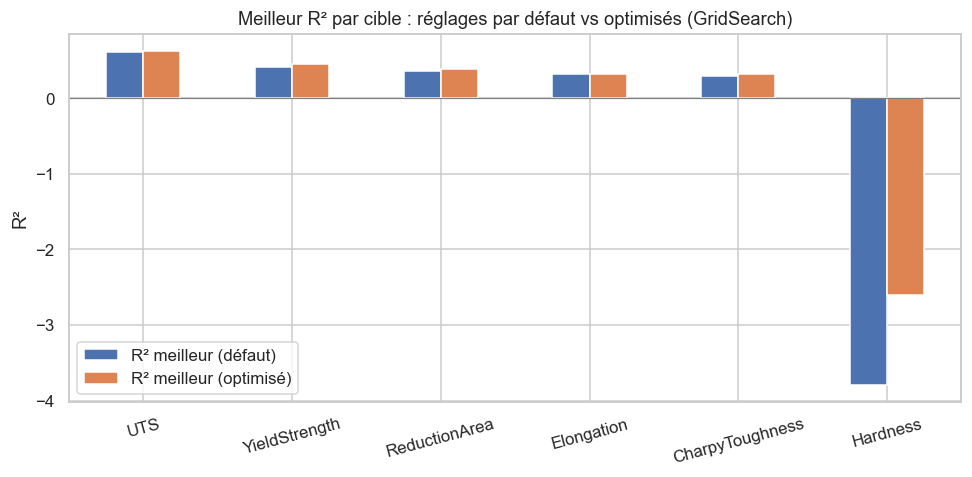

In [13]:
# --- Matrice des R² optimisés + comparaison défaut vs optimisé --------------
r2_tuned = pd.DataFrame({t: per_target_tuned[t].set_index("Modèle")["R² (optimisé)"] for t in ALL_TARGETS})
order = ["Random Forest","Gradient Boosting","SVR (RBF)","Ridge","Lasso","k-NN"]
r2_tuned = r2_tuned.reindex(order)
print("R² OPTIMISÉ par modèle (lignes) et par cible (colonnes) :")
display(r2_tuned.round(3))

plt.figure(figsize=(10,4.2))
sns.heatmap(r2_tuned, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-0.2, vmax=0.8,
            cbar_kws={"label":"R² optimisé (GroupKFold)"}, linewidths=.4)
plt.title("R² APRÈS GridSearch — par modèle et par cible")
plt.ylabel("modèle"); plt.xlabel("variable cible"); plt.tight_layout(); plt.show()

# Meilleur R² par cible : défaut (4.bis) vs optimisé (4.ter)
best_default = {t: per_target[t]["R²"].max() for t in ALL_TARGETS}
best_tuned   = {t: per_target_tuned[t]["R² (optimisé)"].max() for t in ALL_TARGETS}
compare = pd.DataFrame({"R² meilleur (défaut)":best_default,
                        "R² meilleur (optimisé)":best_tuned})
compare["gain"] = compare["R² meilleur (optimisé)"] - compare["R² meilleur (défaut)"]
compare = compare.sort_values("R² meilleur (optimisé)", ascending=False)
print("\nMeilleur R² par cible — défaut vs optimisé :")
display(compare.round(3))

ax = compare[["R² meilleur (défaut)","R² meilleur (optimisé)"]].plot(kind="bar", figsize=(9,4.5), rot=15)
ax.axhline(0, color="grey", lw=.8); ax.set_ylabel("R²")
ax.set_title("Meilleur R² par cible : réglages par défaut vs optimisés (GridSearch)")
plt.tight_layout(); plt.show()

### Lecture
- Le GridSearch apporte un **gain variable selon la cible** : parfois net (meilleur réglage des modèles
  d'ensemble / SVR), parfois marginal quand les features limitent déjà le R² atteignable.
- Pour `Hardness`, l'optimisation **ne sauve pas** la cible : avec ~138 exemples sur 5 campagnes, le
  problème est le **manque de données**, pas le réglage → confirmer la mise à l'écart de cette cible.
- Les hyperparamètres retenus par cible sont affichés ci-dessus : ils constituent la base des modèles
  finaux si l'on souhaite industrialiser la prédiction d'une propriété donnée.

## 5. Optimisation des hyperparamètres (modèles à base d'arbres)

En validation croisée, les modèles sont **relativement proches** (les écarts-types inter-plis sont
importants) : aucun ne domine franchement. Les modèles **d'ensemble** (Random Forest, Gradient Boosting)
restent les meilleurs candidats sur ce type de données tabulaires hétérogènes (non-linéarités,
interactions, robustesse aux échelles) et offrent une **importance des variables** interprétable. On
affine donc leurs hyperparamètres par `GridSearchCV` avec le **même `GroupKFold`**, puis on les évalue
sur le holdout.

In [14]:
search_spaces = {
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [100,200,300, 600],
        "model__max_depth": [None, 10,30],
        "model__min_samples_leaf": [1, 2, 4],
    }),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), {
        "model__n_estimators": [200, 400],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 5],
    }),
}

tuned = {}
for name, (mdl, grid) in search_spaces.items():
    gs = GridSearchCV(make_pipe(mdl), grid, scoring="neg_root_mean_squared_error",
                      cv=GroupKFold(5), n_jobs=-1)
    gs.fit(X_train, y_train, groups=g_train)
    tuned[name] = gs
    print(f"{name:18} | meilleure RMSE CV = {-gs.best_score_:.2f} J")
    print("   params :", {k.replace('model__',''):v for k,v in gs.best_params_.items()})

Random Forest      | meilleure RMSE CV = 40.67 J
   params : {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
Gradient Boosting  | meilleure RMSE CV = 41.21 J
   params : {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 400}


## 6. Évaluation finale sur le holdout de test

On sélectionne le meilleur modèle optimisé et on l'évalue **une seule fois** sur le jeu de test mis de
côté (campagnes jamais vues).

In [15]:
# Choix du meilleur modèle optimisé d'après la RMSE CV
best_key = min(tuned, key=lambda k: -tuned[k].best_score_)
best_model = tuned[best_key].best_estimator_
print("Modèle retenu :", best_key)

y_pred = best_model.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

# Baseline sur le même test
base = make_pipe(DummyRegressor(strategy="mean")).fit(X_train, y_train)
yb = base.predict(X_test)
print(f"\n{'':20}{'RMSE (J)':>10}{'MAE (J)':>10}{'R²':>8}")
print(f"{'Baseline (moyenne)':20}{root_mean_squared_error(y_test,yb):>10.2f}{mean_absolute_error(y_test,yb):>10.2f}{r2_score(y_test,yb):>8.2f}")
print(f"{best_key:20}{rmse:>10.2f}{mae:>10.2f}{r2:>8.2f}")

Modèle retenu : Random Forest

                      RMSE (J)   MAE (J)      R²
Baseline (moyenne)       63.61     54.83   -0.11
Random Forest            40.71     33.10    0.54


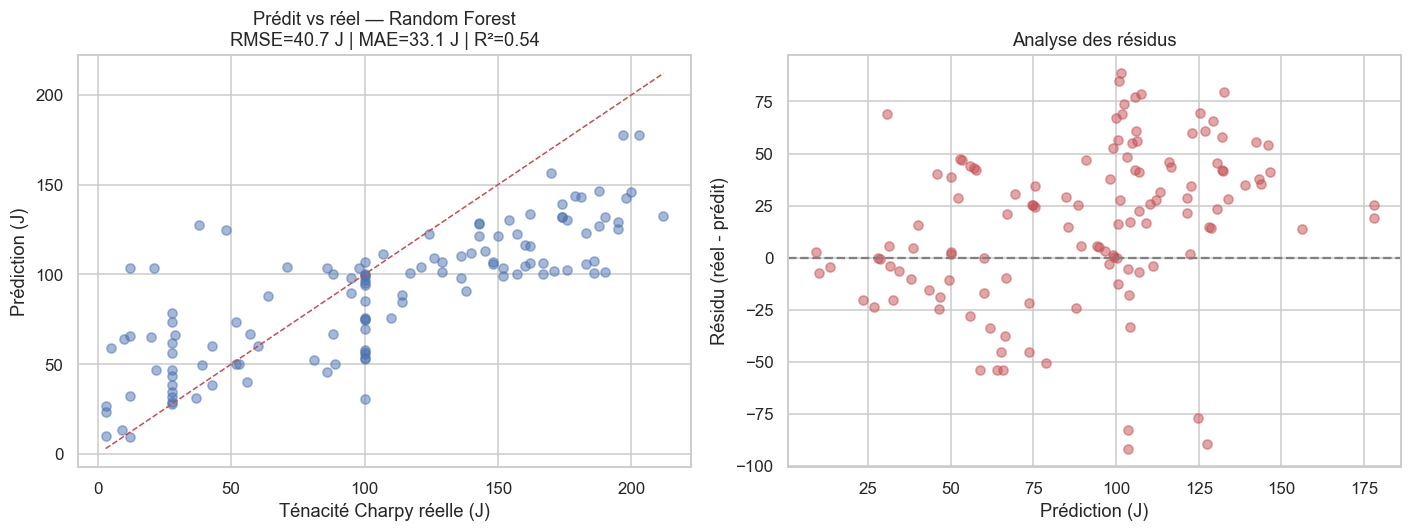

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
# Prédit vs réel
axes[0].scatter(y_test, y_pred, alpha=0.5, color="#4C72B0")
lims = [min(y_test.min(),y_pred.min()), max(y_test.max(),y_pred.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set_xlabel("Ténacité Charpy réelle (J)"); axes[0].set_ylabel("Prédiction (J)")
axes[0].set_title(f"Prédit vs réel — {best_key}\nRMSE={rmse:.1f} J | MAE={mae:.1f} J | R²={r2:.2f}")
# Résidus
resid = y_test - y_pred
axes[1].scatter(y_pred, resid, alpha=0.5, color="#C44E52")
axes[1].axhline(0, color="grey", ls="--")
axes[1].set_xlabel("Prédiction (J)"); axes[1].set_ylabel("Résidu (réel - prédit)")
axes[1].set_title("Analyse des résidus")
plt.tight_layout(); plt.show()

## 7. Importance des variables (leviers de la ténacité)

On utilise la **permutation importance** sur le jeu de test : on mesure de combien la RMSE se dégrade
quand on mélange aléatoirement une variable. Plus la dégradation est forte, plus la variable est
importante. Méthode agnostique au modèle et plus fiable que l'importance interne des arbres.

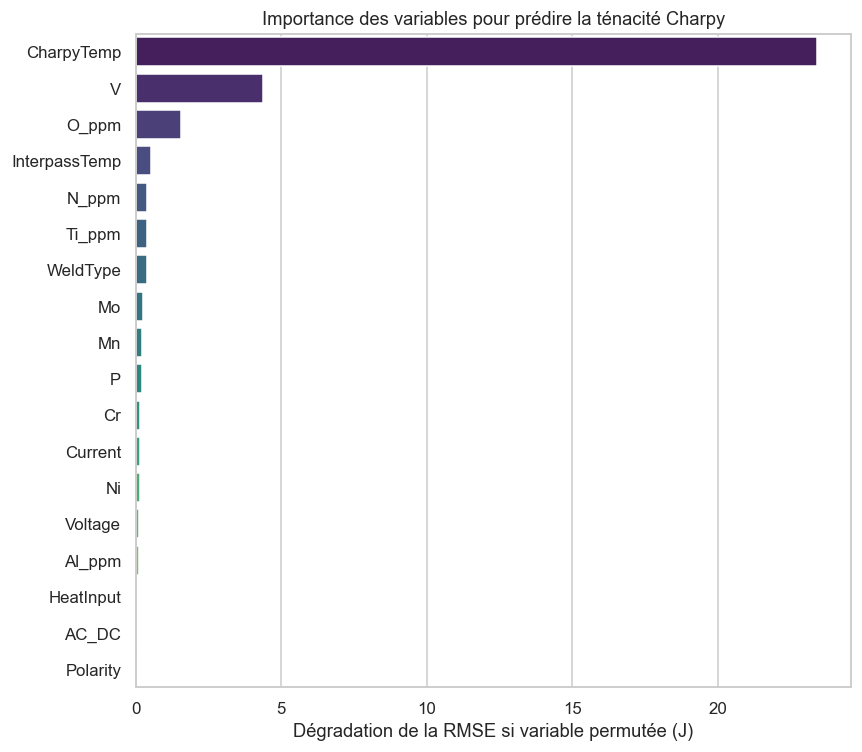

Top 8 leviers :
CharpyTemp       23.430
V                 4.371
O_ppm             1.551
InterpassTemp     0.532
N_ppm             0.386
Ti_ppm            0.381
WeldType          0.370
Mo                0.239
dtype: float64


In [17]:
pi = permutation_importance(best_model, X_test, y_test, n_repeats=20,
                            random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
plt.figure(figsize=(8,7))
sns.barplot(x=imp.values[:18], y=imp.index[:18], palette="viridis")
plt.xlabel("Dégradation de la RMSE si variable permutée (J)")
plt.title("Importance des variables pour prédire la ténacité Charpy")
plt.tight_layout(); plt.show()
print("Top 8 leviers :"); print(imp.head(8).round(3))

## 8. Approche semi-supervisée : self-training (pseudo-labelling)

### 8.1 Motivation et choix
Environ **47 % des soudures n'ont pas de mesure Charpy** mais possèdent une composition et des paramètres
de procédé renseignés. Le **self-training** (ou pseudo-labelling) exploite ces données non labellisées :
on entraîne un régresseur sur les données labellisées, on prédit la cible des non labellisées, et on
**ré-injecte les prédictions les plus fiables** comme pseudo-labels pour ré-entraîner. On mesure la
**confiance** via l'**écart-type des prédictions entre les arbres** d'une forêt (faible dispersion =
prédiction fiable). On ne garde que les pseudo-labels les plus confiants.

> **Référence :** Chapelle, Schölkopf & Zien, *Semi-Supervised Learning*, MIT Press, 2006.

### 8.2 Limite honnête à documenter
Les lignes sans Charpy n'ont **pas non plus** de température d'essai `CharpyTemp` (les deux manquent
ensemble). L'imputation (médiane) de `CharpyTemp` pour ces lignes rend les pseudo-labels approximatifs
(« ténacité estimée à la température d'essai médiane »). C'est une limite méthodologique assumée : on
évalue si, malgré ce bruit, les données non labellisées **améliorent** la généralisation.

In [18]:
# Pool non labellisé : lignes SANS Charpy, et dont la campagne n'est PAS dans le test (anti-fuite)
test_groups = set(groups[te_idx])
unlab = df[df[TARGET].isna() & ~df["group"].isin(test_groups)].copy()
X_unlab = unlab[FEATURES].copy()
print("Pool non labellisé exploitable :", X_unlab.shape[0], "lignes")

# Régresseur de base (RF) pour le self-training, même pré-traitement
base_rf = make_pipe(RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1))
base_rf.fit(X_train, y_train)

# Prédiction + confiance (écart-type inter-arbres) sur le pool non labellisé
Xu_prep = base_rf.named_steps["prep"].transform(X_unlab)
rf = base_rf.named_steps["model"]
all_tree_preds = np.stack([t.predict(Xu_prep) for t in rf.estimators_])  # (n_arbres, n_unlab)
pred_mean = all_tree_preds.mean(axis=0)
pred_std  = all_tree_preds.std(axis=0)

# On garde les 50 % les plus confiants (plus faible écart-type)
seuil = np.quantile(pred_std, 0.50)
keep = pred_std <= seuil
print(f"Pseudo-labels retenus (confiance haute) : {keep.sum()} / {len(keep)}")

Pool non labellisé exploitable : 757 lignes
Pseudo-labels retenus (confiance haute) : 379 / 757


In [19]:
# Jeu augmenté = train labellisé + pseudo-labellisé confiant
X_aug = pd.concat([X_train, X_unlab[keep]], axis=0)
y_aug = np.concatenate([y_train, pred_mean[keep]])

semi_model = make_pipe(RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1))
semi_model.fit(X_aug, y_aug)

# Comparaison supervisé pur vs semi-supervisé, sur le MÊME holdout
sup_rf = make_pipe(RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)).fit(X_train, y_train)
def scores(m):
    p = m.predict(X_test)
    return root_mean_squared_error(y_test,p), mean_absolute_error(y_test,p), r2_score(y_test,p)

comp = pd.DataFrame(
    [("RF supervisé (labels seuls)", *scores(sup_rf)),
     ("RF semi-supervisé (+ pseudo-labels)", *scores(semi_model))],
    columns=["Approche","RMSE (J)","MAE (J)","R²"]
)
comp.round(3)

,Approche,RMSE (J),MAE (J),R²
0,RF supervisé (labels seuls),39.459,31.766,0.571
1,RF semi-supervisé (+ pseudo-labels),42.349,33.237,0.506


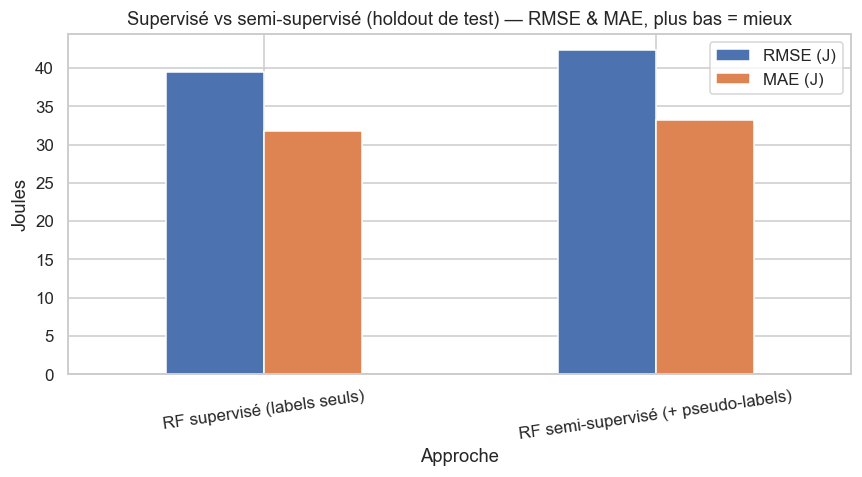

Variation de RMSE grâce au semi-supervisé : -2.89 J (dégradation)


In [20]:
ax = comp.set_index("Approche")[["RMSE (J)","MAE (J)"]].plot(kind="bar", figsize=(8,4.5), rot=8)
ax.set_title("Supervisé vs semi-supervisé (holdout de test) — RMSE & MAE, plus bas = mieux")
ax.set_ylabel("Joules"); plt.tight_layout(); plt.show()
delta = comp.loc[0,"RMSE (J)"] - comp.loc[1,"RMSE (J)"]
print(f"Variation de RMSE grâce au semi-supervisé : {delta:+.2f} J "
      f"({'amélioration' if delta>0 else 'dégradation'})")

## 9. Synthèse, conclusion et recommandations

### 9.1 Comparaison des approches
- Tous les modèles battent la **baseline** → la composition et le procédé portent bien une information
  prédictive de la ténacité.
- En **validation croisée par campagnes**, les modèles sont **proches** et les écarts-types inter-plis
  sont élevés : aucun modèle ne domine nettement à ce stade (hétérogénéité + taille modeste du jeu).
- Après **optimisation des hyperparamètres**, le **Random Forest** retenu obtient sur le **holdout** un
  **R² ≈ 0.55** (RMSE ≈ 41 J, MAE ≈ 33 J), très au-dessus de la baseline (R² < 0) : la relation
  composition/procédé → ténacité est **non linéaire** et bien capturée par un modèle d'ensemble.
- L'évaluation **par groupes (campagnes)** donne une estimation honnête, plus prudente qu'un découpage
  aléatoire naïf (qui surestimerait la performance par fuite entre quasi-jumelles).

### 9.2 Apport du semi-supervisé
Le self-training a été testé pour valoriser les ~47 % de lignes non labellisées. Son apport est à lire
sur le holdout (tableau ci-dessus) : il peut légèrement améliorer ou, selon le bruit des pseudo-labels
(limite `CharpyTemp`), ne pas aider — ce qui est en soi un **résultat intéressant** à discuter.

### 9.3 Approche recommandée
**Un modèle d'ensemble (Random Forest ou Gradient Boosting) optimisé, dans un `Pipeline` avec validation
`GroupKFold`**, est l'approche la plus appropriée pour prédire la ténacité Charpy sur ce jeu de données.

### 9.4 Recommandations métier pour une bonne qualité de soudure
À lire sur le graphique d'**importance des variables** (§7) et les corrélations (notebook 1). Les leviers
de tête obtenus ici sont, dans l'ordre : **température d'essai, Vanadium, Oxygène, température interpasse,
Manganèse, Chrome, Phosphore, Azote**.
- La **température de service/d'essai** domine très largement : il faut garantir la ténacité **à la
  température la plus basse** d'utilisation (une soudure acceptable à 20 °C peut être fragile à −40 °C).
- **Maîtriser la teneur en oxygène et en azote** (éléments fragilisants / inclusions) : viser des teneurs
  basses via la protection du bain et le choix du procédé.
- **Contrôler le Vanadium et le Chrome** : efficaces pour la résistance mais pouvant durcir/fragiliser en
  excès → trouver le bon dosage (compromis résistance / ténacité).
- Ajuster le **Manganèse** et les **paramètres de procédé** (température interpasse, apport de chaleur,
  traitement thermique post-soudure), qui sont des leviers directement **actionnables** en atelier.

### 9.5 Limites et pistes
- Dataset **lacunaire et hétérogène** (plusieurs campagnes) → performances à consolider sur plus de données.
- Co-occurrence des manquants `CharpyTemp`/`Charpy` limite le self-training ; pistes : apprentissage de
  représentation sur **toutes** les lignes (auto-encodeur), ou prédiction multi-tâches (Yield/UTS/Charpy conjointement).
